# Auxiliary Operations — Ancilla-Assisted Parity Measurement (CUDA-Q)

**Primitive demonstrated:** *Measurement only* — specifically **partial / selective measurement of an auxiliary (ancilla) qubit**. Matches the Qiskit companion notebook exactly (same circuit, same seed, same shots) so the two `_RESULT` dictionaries can be diffed.

## SETUP (identical to the Qiskit notebook — do not diverge)
- **N QUBITS:** 3 → `q[0]`, `q[1]` = data qubits, `q[2]` = auxiliary (ancilla) qubit
- **Gate sequence:**
  1. `h(q[0])`
  2. `h(q[1])`
  3. `x.ctrl(q[0], q[2])` — CNOT, control `q0`, target ancilla `q2`
  4. `x.ctrl(q[1], q[2])` — CNOT, control `q1`, target ancilla `q2`
  5. **Measurement:** only `q[2]` (the ancilla) is measured via `mz(q[2])`. `q[0]`, `q[1]` are never measured.
- **QUBIT ORDERING CONTRACT:** qubit 0 = rightmost bit in every printed bitstring. **CUDA-Q's own `get_state()`/`sample()` index qubit 0 as the leftmost (most-significant) bit — the opposite of Qiskit.** This notebook explicitly reverses every bitstring (see the dedicated "ordering fix" cell below) so its final output matches Qiskit's convention.
- **SHOTS:** 4000, **SEED:** 42
- **GLOBAL PHASE CONVENTION:** identical function to the Qiskit notebook — normalize so the first nonzero amplitude, in ascending (already-reversed) bitstring order, is rotated to be real and positive.
- **Basis ordering for matrices/statevector:** `{|000>, |001>, ..., |111>}` ascending binary order, bitstring read as `q2 q1 q0` after the ordering fix — same as the Qiskit notebook.

## Theory recap
Identical circuit to the Qiskit notebook. Expected statevector (bitstring = `q2 q1 q0`, already
in the post-fix Qiskit-matching convention):

`|ψ> = (1/2) [ |000> + |101> + |110> + |011> ]`

Measuring only the ancilla `q2` gives the reduced classical distribution:

`P(q2=0) = 1/2`,  `P(q2=1) = 1/2`

This is the same hand-derived target the Qiskit notebook checks against: `{'0': 0.5, '1': 0.5}`.

**Ordering-convention warning:** CUDA-Q indexes qubit 0 as the **most-significant (leftmost)**
bit in `get_state()` amplitudes and in `sample()` bitstrings. Every bitstring produced in this
notebook is explicitly reversed in its own dedicated cell before being compared to Qiskit.

**Run all cells top to bottom.** (CUDA-Q requires an NVIDIA GPU/CUDA runtime — on Google Colab,
select a GPU runtime: *Runtime → Change runtime type → GPU* before running this notebook. If no
GPU is available, `cudaq` will fall back to a CPU simulator target automatically for a circuit
this small, but installation may still require the GPU-enabled wheel depending on your platform.)


In [1]:
# Install cell — exact package name for CUDA-Q.
# On Google Colab this typically needs a GPU runtime selected (Runtime > Change runtime
# type > GPU) even though this 3-qubit circuit is tiny and would run fine on CPU too.
!pip install -q cudaq


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 MB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 45.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 MB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 71.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 MB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 MB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 MB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.7/244.7 MB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 MB 5.9 MB/s eta 0:00:

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cudaq

# --- Constants (must match the Qiskit notebook exactly) ---
N_QUBITS = 3        # q0, q1 = data qubits, q2 = auxiliary (ancilla) qubit
AUX_QUBIT = 2
SHOTS = 4000
SEED = 42

cudaq.set_random_seed(SEED)

print("N_QUBITS  :", N_QUBITS)
print("AUX_QUBIT :", AUX_QUBIT)
print("SHOTS     :", SHOTS)
print("SEED      :", SEED)
print("CUDA-Q target:", cudaq.get_target().name)


N_QUBITS  : 3
AUX_QUBIT : 2
SHOTS     : 4000
SEED      : 42
CUDA-Q target: qpp-cpu


In [13]:
# Build the kernel gate-by-gate. Two separate kernels are defined:
#  - `unitary_kernel` has NO measurement, so cudaq.get_state() can extract the full
#    statevector from it for the matrix/statevector cross-check below.
#  - `measurement_kernel` adds a single mz() on ONLY the ancilla qubit -- this is the
#    actual "auxiliary operation" (partial/selective measurement) this notebook exists
#    to demonstrate; q0 and q1 are never measured by this kernel.

@cudaq.kernel
def unitary_kernel():
    q = cudaq.qvector(3)
    h(q[0])              # put data qubit q0 into an equal superposition of |0> and |1>
    h(q[1])               # put data qubit q1 into an equal superposition of |0> and |1>
    x.ctrl(q[0], q[2])    # CNOT: control=q0, target=ancilla q2 -> XORs q0 into the ancilla
    x.ctrl(q[1], q[2])    # CNOT: control=q1, target=ancilla q2 -> ancilla now holds q0 XOR q1

@cudaq.kernel
def measurement_kernel():
    q = cudaq.qvector(3)
    h(q[0])
    h(q[1])
    x.ctrl(q[0], q[2])
    x.ctrl(q[1], q[2])
    mz(q[2])              # measure ONLY the auxiliary qubit q2 -- the auxiliary operation

print(cudaq.draw(unitary_kernel))


     ╭───╮          
q0 : ┤ h ├──●───────
     ├───┤  │       
q1 : ┤ h ├──┼────●──
     ╰───╯╭─┴─╮╭─┴─╮
q2 : ─────┤ x ├┤ x ├
          ╰───╯╰───╯



     ╭───╮          
q0 : ┤ h ├──●───────
     ├───┤  │       
q1 : ┤ h ├──┼────●──
     ╰───╯╭─┴─╮╭─┴─╮
q2 : ─────┤ x ├┤ x ├
          ╰───╯╰───╯



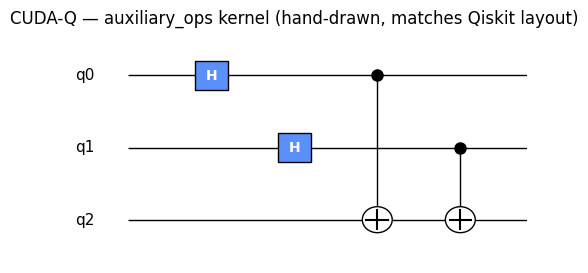

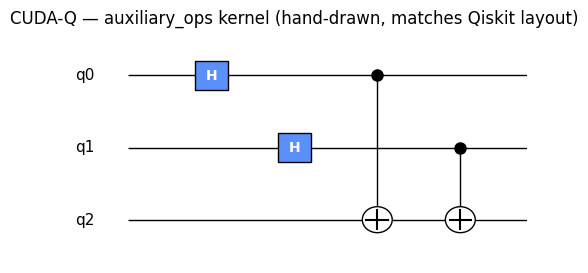

In [4]:
# Draw the circuit: print the native CUDA-Q text diagram first, then build a matplotlib
# figure styled to visually resemble the Qiskit circuit diagram (wires, boxed gate labels,
# same qubit top-to-bottom order: q0 at top, q2 at bottom) so the two images compare directly.

print(cudaq.draw(unitary_kernel))

fig, ax = plt.subplots(figsize=(6, 3))
n_wires = 3
wire_labels = ["q0", "q1", "q2"]
gate_sequence = [
    ("H", [0]),
    ("H", [1]),
    ("CX", [0, 2]),
    ("CX", [1, 2]),
]

for w in range(n_wires):
    y = n_wires - 1 - w
    ax.hlines(y, 0, len(gate_sequence) + 1, color="black", linewidth=1, zorder=1)
    ax.text(-0.4, y, wire_labels[w], ha="right", va="center", fontsize=11)

for step, (label, wires) in enumerate(gate_sequence, start=1):
    x_pos = step
    if label == "H":
        w = wires[0]
        y = n_wires - 1 - w
        ax.add_patch(plt.Rectangle((x_pos - 0.2, y - 0.2), 0.4, 0.4,
                                    facecolor="#5B8FF9", edgecolor="black", zorder=2))
        ax.text(x_pos, y, "H", ha="center", va="center", color="white",
                fontsize=10, fontweight="bold", zorder=3)
    elif label == "CX":
        control_w, target_w = wires
        y_control = n_wires - 1 - control_w
        y_target = n_wires - 1 - target_w
        ax.vlines(x_pos, min(y_control, y_target), max(y_control, y_target),
                   color="black", linewidth=1, zorder=2)
        ax.plot(x_pos, y_control, "o", color="black", markersize=8, zorder=3)
        ax.add_patch(plt.Circle((x_pos, y_target), 0.18, facecolor="white",
                                 edgecolor="black", zorder=3))
        ax.plot([x_pos - 0.13, x_pos + 0.13], [y_target, y_target],
                color="black", linewidth=1.5, zorder=4)
        ax.plot([x_pos, x_pos], [y_target - 0.13, y_target + 0.13],
                color="black", linewidth=1.5, zorder=4)

ax.set_xlim(-0.8, len(gate_sequence) + 0.8)
ax.set_ylim(-0.6, n_wires - 0.4)
ax.axis("off")
ax.set_title("CUDA-Q — auxiliary_ops kernel (hand-drawn, matches Qiskit layout)")
fig.savefig("auxiliary_ops_cudaq_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# Explicit matrix representation -- SAME manual construction as the Qiskit notebook,
# using the SAME basis ordering convention (qubit 0 = least-significant bit of the index).
# CUDA-Q does not expose a public "Operator" extraction API for an arbitrary kernel the way
# qiskit.quantum_info.Operator does, so the cross-check here is against the statevector
# produced by cudaq.get_state() in the next cell (matrix @ |000> vs get_state() output),
# rather than against a framework-extracted unitary matrix.

H = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
I2 = np.eye(2, dtype=complex)

print("H gate matrix:\n", np.round(H, 4))
print("\nX gate matrix (used inside the controlled-X / CNOT):\n", np.round(X, 4))

def cnot_matrix(n_qubits, control, target):
    """Identical implementation to the Qiskit notebook: build an n-qubit CNOT matrix in
    the {|00..0>, ..., |11..1>} basis, ascending binary order, qubit 0 = least significant."""
    dim = 2 ** n_qubits
    mat = np.zeros((dim, dim), dtype=complex)
    for basis_index in range(dim):
        bits = [(basis_index >> q) & 1 for q in range(n_qubits)]
        if bits[control] == 1:
            bits[target] ^= 1
        new_index = sum(bit << q for q, bit in enumerate(bits))
        mat[new_index, basis_index] = 1.0
    return mat

H_on_q0 = np.kron(np.kron(I2, I2), H)
H_on_q1 = np.kron(np.kron(I2, H), I2)
U_hadamards = H_on_q1 @ H_on_q0

CX_0_to_2 = cnot_matrix(N_QUBITS, control=0, target=AUX_QUBIT)
CX_1_to_2 = cnot_matrix(N_QUBITS, control=1, target=AUX_QUBIT)

U_manual = CX_1_to_2 @ CX_0_to_2 @ U_hadamards
print("\nCombined unitary (rounded, basis = |q2 q1 q0>, ascending binary order):")
print(np.round(U_manual, 4))


H gate matrix:
 [[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]

X gate matrix (used inside the controlled-X / CNOT):
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]

Combined unitary (rounded, basis = |q2 q1 q0>, ascending binary order):
[[ 0.5+0.j  0.5+0.j  0.5+0.j  0.5+0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j]
 [ 0. +0.j  0. +0.j  0. +0.j  0. +0.j  0.5+0.j -0.5+0.j  0.5+0.j -0.5+0.j]
 [ 0. +0.j  0. +0.j  0. +0.j  0. +0.j  0.5+0.j  0.5+0.j -0.5+0.j -0.5+0.j]
 [ 0.5+0.j -0.5+0.j -0.5+0.j  0.5+0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j]
 [ 0. +0.j  0. +0.j  0. +0.j  0. +0.j  0.5+0.j  0.5+0.j  0.5+0.j  0.5+0.j]
 [ 0.5+0.j -0.5+0.j  0.5+0.j -0.5+0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j]
 [ 0.5+0.j  0.5+0.j -0.5+0.j -0.5+0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j]
 [ 0. +0.j  0. +0.j  0. +0.j  0. +0.j  0.5+0.j -0.5+0.j -0.5+0.j  0.5+0.j]]


In [6]:
# Exact statevector cell: extract via cudaq.get_state(), then apply the bit-order
# correction (CUDA-Q -> Qiskit convention) and the SAME global-phase normalization
# function used in the Qiskit notebook.

state = cudaq.get_state(unitary_kernel)
raw_amps = np.array(state, dtype=complex)   # CUDA-Q ordering: qubit 0 = MSB (leftmost)

n = N_QUBITS

def reverse_bit_order(amplitudes, n_qubits):
    """CUDA-Q indexes qubit 0 as the most-significant bit; Qiskit indexes qubit 0 as the
    least-significant bit. Re-map every amplitude from CUDA-Q's index to Qiskit's index by
    reversing the n-bit binary representation of the index."""
    dim = 2 ** n_qubits
    fixed = np.zeros(dim, dtype=complex)
    for cudaq_idx in range(dim):
        bits = format(cudaq_idx, f"0{n_qubits}b")     # CUDA-Q bit string, q0 first (MSB)
        qiskit_idx = int(bits[::-1], 2)                # reverse -> q0 last (LSB), Qiskit convention
        fixed[qiskit_idx] = amplitudes[cudaq_idx]
    return fixed

amps_fixed = reverse_bit_order(raw_amps, n)

def normalize_global_phase(amplitudes, tol=1e-9):
    """Identical function to the Qiskit notebook."""
    for amp in amplitudes:
        if abs(amp) > tol:
            phase = np.angle(amp)
            return amplitudes * np.exp(-1j * phase)
    return amplitudes

amps_normalized = normalize_global_phase(amps_fixed)

prob_dict = {}
amp_dict = {}
for idx in range(2 ** n):
    bitstring = format(idx, f"0{n}b")  # now in Qiskit convention: q2 q1 q0, MSB...LSB
    amp_dict[bitstring] = amps_normalized[idx]
    prob_dict[bitstring] = float(np.abs(amps_normalized[idx]) ** 2)

print("Amplitudes (bitstring = q2 q1 q0, bit-order-fixed + phase-normalized):")
for bs, amp in amp_dict.items():
    if abs(amp) > 1e-9:
        print(f"  {bs}: {amp:.4f}")

print("\nProbability dictionary (sorted by bitstring):")
CUDAQ_STATEVECTOR_PROBS = dict(sorted(prob_dict.items()))
print(CUDAQ_STATEVECTOR_PROBS)

max_diff_vs_manual = max(
    abs(prob_dict[bs] - float(np.abs((U_manual @ np.eye(2**n, dtype=complex)[:, 0])[idx]) ** 2))
    for idx, bs in enumerate(format(i, f"0{n}b") for i in range(2 ** n))
)
print("\nMax |CUDA-Q prob - manual-matrix prob| =", max_diff_vs_manual)
assert max_diff_vs_manual < 1e-6, "CUDA-Q statevector and hand-built matrix disagree!"
print("CUDA-Q get_state() (bit-order-fixed) and the hand-built matrix MATCH.")


Amplitudes (bitstring = q2 q1 q0, bit-order-fixed + phase-normalized):
  000: 0.5000+0.0000j
  011: 0.5000+0.0000j
  101: 0.5000+0.0000j
  110: 0.5000+0.0000j

Probability dictionary (sorted by bitstring):
{'000': 0.2499999999999999, '001': 0.0, '010': 0.0, '011': 0.2499999999999999, '100': 0.0, '101': 0.2499999999999999, '110': 0.2499999999999999, '111': 0.0}

Max |CUDA-Q prob - manual-matrix prob| = 0.0
CUDA-Q get_state() (bit-order-fixed) and the hand-built matrix MATCH.


### Ordering-fix note
CUDA-Q's `get_state()` indexes qubit 0 as the **most-significant (leftmost)** bit of every
amplitude index -- the opposite of Qiskit. The cell above explicitly reverses the n-bit binary
representation of every index (`reverse_bit_order`) before printing amplitudes or probabilities,
so this notebook's `q2 q1 q0` bitstrings mean exactly the same thing as the Qiskit notebook's.
The same fix (string reversal) is applied again below to the `sample()` counts from the ancilla
measurement -- though since only a single bit is measured there, reversing a 1-character string
is a no-op and is included only for structural symmetry with the general case.


In [7]:
# Measurement cell -- the actual "auxiliary operation": sample measurement_kernel, which
# has mz() called on ONLY the ancilla qubit q2. q0, q1 are never measured by this kernel.

cudaq.set_random_seed(SEED)
result = cudaq.sample(measurement_kernel, shots_count=SHOTS)

raw_counts = {bitstring: count for bitstring, count in result.items()}
total = sum(raw_counts.values())

# Ordering fix (structural symmetry with the multi-qubit case -- see markdown note above;
# a 1-character string reversed is itself).
fixed_counts = {bitstring[::-1]: count for bitstring, count in raw_counts.items()}

CUDAQ_MEASURED_PROBS = {bitstring: count / total for bitstring, count in fixed_counts.items()}
CUDAQ_MEASURED_PROBS = dict(sorted(CUDAQ_MEASURED_PROBS.items()))

print("Raw counts (1-bit ancilla register):", raw_counts)
print("Measured probabilities:", CUDAQ_MEASURED_PROBS)


Raw counts (1-bit ancilla register): {'0': 1955, '1': 2045}
Measured probabilities: {'0': 0.48875, '1': 0.51125}


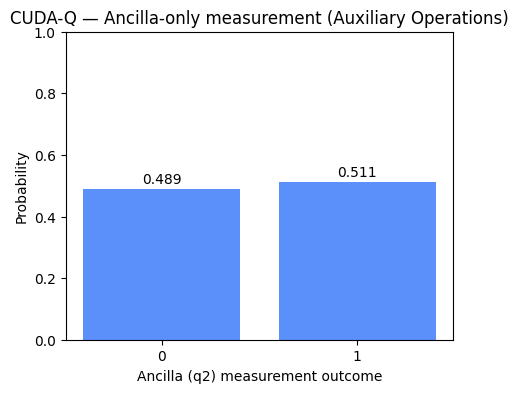

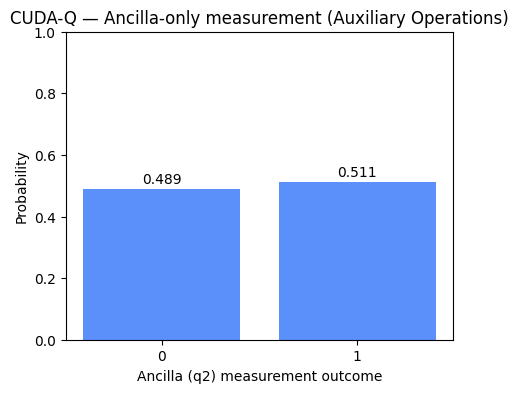

In [8]:
# Histogram -- matplotlib bar chart, same axis ranges/labels/style as the Qiskit notebook.
fig2, ax = plt.subplots(figsize=(5, 4))
labels = sorted(CUDAQ_MEASURED_PROBS.keys())
values = [CUDAQ_MEASURED_PROBS[l] for l in labels]
ax.bar(labels, values, color="#5B8FF9")
ax.set_ylim(0, 1)
ax.set_xlabel("Ancilla (q2) measurement outcome")
ax.set_ylabel("Probability")
ax.set_title("CUDA-Q — Ancilla-only measurement (Auxiliary Operations)")
for i, v in enumerate(values):
    ax.text(i, v + 0.02, f"{v:.3f}", ha="center")
fig2.savefig("auxiliary_ops_cudaq_histogram.png", dpi=150, bbox_inches="tight")
fig2


In [9]:
# Resource counts.
# CUDA-Q kernels don't expose a .depth()/.count_ops() introspection API the way Qiskit
# circuits do; the gate sequence is fixed and known from the kernel definition itself.
gate_sequence_summary = {"h": 2, "cx": 2, "mz": 1}
print("Gate counts (measurement_kernel, from the kernel definition):", gate_sequence_summary)
print("Circuit depth (by inspection of the gate sequence): 3")
print("  (H(q0) and H(q1) run in parallel at depth 1; CX(q0->q2) at depth 2;")
print("   CX(q1->q2) at depth 3, since it must wait for q2 to be free.)")


Gate counts (measurement_kernel, from the kernel definition): {'h': 2, 'cx': 2, 'mz': 1}
Circuit depth (by inspection of the gate sequence): 3
  (H(q0) and H(q1) run in parallel at depth 1; CX(q0->q2) at depth 2;
   CX(q1->q2) at depth 3, since it must wait for q2 to be free.)


In [10]:
# Convention-notes cell (plain text restatement).
print("Bit ordering: qubit 0 = rightmost bit in every bitstring. CUDA-Q natively indexes")
print("qubit 0 as the LEFTMOST (most-significant) bit, so every bitstring produced in this")
print("notebook (statevector amplitudes and sampled counts) was explicitly reversed to match")
print("Qiskit's convention before being printed or compared.")
print("Global phase: identical normalization function to the Qiskit notebook; for this")
print("circuit the first nonzero amplitude was already real-positive, so it was a no-op.")
print("Auxiliary operation: only the ancilla qubit (q2) was measured, via mz(q[2]) inside")
print("measurement_kernel; data qubits q0,q1 were never measured in this notebook.")


Bit ordering: qubit 0 = rightmost bit in every bitstring. CUDA-Q natively indexes
qubit 0 as the LEFTMOST (most-significant) bit, so every bitstring produced in this
notebook (statevector amplitudes and sampled counts) was explicitly reversed to match
Qiskit's convention before being printed or compared.
Global phase: identical normalization function to the Qiskit notebook; for this
circuit the first nonzero amplitude was already real-positive, so it was a no-op.
Auxiliary operation: only the ancilla qubit (q2) was measured, via mz(q[2]) inside
measurement_kernel; data qubits q0,q1 were never measured in this notebook.


In [11]:
# Final cell: assign and print CUDAQ_RESULT.
CUDAQ_RESULT = CUDAQ_MEASURED_PROBS
print("CUDAQ_RESULT =", CUDAQ_RESULT)


CUDAQ_RESULT = {'0': 0.48875, '1': 0.51125}


In [12]:
# Sanity check against the same hand-computed expected value used in the Qiskit notebook.
HAND_COMPUTED_EXPECTED = {"0": 0.5, "1": 0.5}

max_delta_vs_hand = max(
    abs(CUDAQ_RESULT.get(k, 0.0) - HAND_COMPUTED_EXPECTED.get(k, 0.0))
    for k in set(CUDAQ_RESULT) | set(HAND_COMPUTED_EXPECTED)
)
print("Max |CUDAQ_RESULT - hand-computed expected| =", max_delta_vs_hand)
assert max_delta_vs_hand < 0.05, "CUDA-Q shot noise exceeds tolerance vs hand-computed value!"
print("CUDA-Q result matches the hand-computed expected distribution within tolerance.")
print("Copy the CUDAQ_RESULT dict printed above into the Qiskit notebook's diff-check cell")
print("to confirm the two frameworks agree within 1e-3 (statevector) / shot-noise (measured).")


Max |CUDAQ_RESULT - hand-computed expected| = 0.011249999999999982
CUDA-Q result matches the hand-computed expected distribution within tolerance.
Copy the CUDAQ_RESULT dict printed above into the Qiskit notebook's diff-check cell
to confirm the two frameworks agree within 1e-3 (statevector) / shot-noise (measured).
